# Nylon SURFMAP — concentric ROI circles (5–25 px)

This notebook draws **black circular perimeters** on a complete nylon PNG map without cropping the image.

The circle centre follows the same rule used in the previous protein ROI notebook:

```python
center_x = image_width // 2
center_y = image_height // 2
```

### Recommended input
Use the `*_map_clean.png` image whenever possible, because it contains only the map and does not include axes, title or external margins. The notebook can also open the plotted version, but in that case the geometrical centre of the PNG may not exactly coincide with the centre of the actual map.

### Output
- one **full-size PNG** for every radius;
- the output directory is created automatically;
- all generated maps are displayed in the notebook;
- default radii are **5 to 25 px inclusive** (21 maps).


In [71]:
from pathlib import Path
from math import ceil

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw


## Parameters

Change only this cell for a different nylon map, output folder, radius range or line thickness.

`FILENAME_LABEL_MULTIPLIER = 2` reproduces the requested naming convention:

- radius 5 px → `_10A`
- radius 6 px → `_12A`
- ...
- radius 25 px → `_50A`

This multiplier affects **only the filename label**. It does not change the circle radius.


In [72]:
# -----------------------------------------------------------------------------
# INPUT / OUTPUT
# -----------------------------------------------------------------------------

MAP_PATH = Path(
    r"/home/chiara/Desktop/COMENZE/Surfmatch_pipeline/Nylon_surface/Nylon_surfmap/surfmap_cubes_batch_rad0.5_s2/03_Nylon7415_70A_final_clean_aligned/output_SURFMAP_03_Nylon7415_70A_final_clean_aligned_bfactor/maps/03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean.png"
)

# Change this path as needed. The folder is created automatically.
OUTPUT_DIR = Path(
    r"/home/chiara/Desktop/COMENZE/Surfmatch_pipeline/Nylon_surface/Nylon_surfmap/"
    r"nylon_ROI_circles"
)


# -----------------------------------------------------------------------------
# CIRCLE PARAMETERS
# -----------------------------------------------------------------------------

RADIUS_MIN = 5
RADIUS_MAX = 25
RADIUS_STEP = 1

# Thin black perimeter. Increase to 2 if the PNG is very large.
CIRCLE_WIDTH = 1
CIRCLE_COLOR = (0, 0, 0, 255)


# -----------------------------------------------------------------------------
# FILENAME PARAMETERS
# -----------------------------------------------------------------------------

# Only controls the output label.
# With 2: radius 5 px -> _10A, radius 6 px -> _12A, etc.
FILENAME_LABEL_MULTIPLIER = 2

# Number of maps per row in the notebook preview.
PREVIEW_COLUMNS = 5


# Build the radius list, including RADIUS_MAX.
RADIUS_VALUES = list(range(RADIUS_MIN, RADIUS_MAX + 1, RADIUS_STEP))

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Input map:", MAP_PATH)
print("Output directory:", OUTPUT_DIR)
print("Radii:", RADIUS_VALUES)
print("Number of maps:", len(RADIUS_VALUES))


Input map: /home/chiara/Desktop/COMENZE/Surfmatch_pipeline/Nylon_surface/Nylon_surfmap/surfmap_cubes_batch_rad0.5_s2/03_Nylon7415_70A_final_clean_aligned/output_SURFMAP_03_Nylon7415_70A_final_clean_aligned_bfactor/maps/03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean.png
Output directory: /home/chiara/Desktop/COMENZE/Surfmatch_pipeline/Nylon_surface/Nylon_surfmap/nylon_ROI_circles
Radii: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
Number of maps: 21


## Functions

The image is never cropped or rescaled. A copy of the complete PNG is created for each radius and only the black circle perimeter is added.


In [73]:
def filename_label(radius_px):
    """Create the label used only in the output filename."""
    value = radius_px * FILENAME_LABEL_MULTIPLIER

    if float(value).is_integer():
        value = int(value)

    return f"{value}px"


def draw_centered_circle(image, radius_px, center_xy, line_width=1):
    """Return a full-size copy of image with a centred black circle."""
    output = image.copy().convert("RGBA")
    draw = ImageDraw.Draw(output)

    center_x, center_y = center_xy

    bounding_box = (
        center_x - radius_px,
        center_y - radius_px,
        center_x + radius_px,
        center_y + radius_px,
    )

    draw.ellipse(
        bounding_box,
        outline=CIRCLE_COLOR,
        width=line_width,
    )

    return output


## Load the nylon map and determine its centre

This is the same centre convention as the old protein script: integer midpoint of map width and height.


Image size: 180 x 90 px
Map centre: x=90, y=50
Largest circle fully contained in image: 39 px


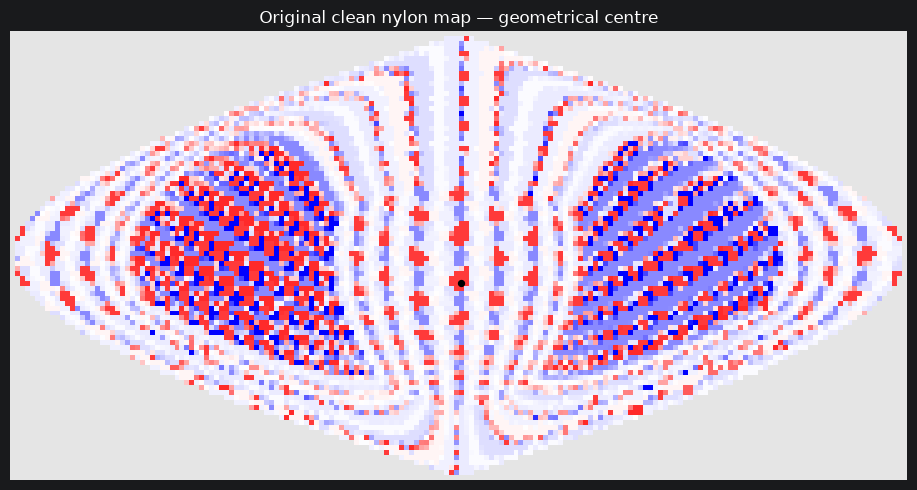

In [74]:
if not MAP_PATH.is_file():
    raise FileNotFoundError(
        f"PNG map not found:\n{MAP_PATH}\n\n"
        "Change MAP_PATH in the parameter cell."
    )

original_image = Image.open(MAP_PATH).convert("RGBA")
image_width, image_height = original_image.size

center_x = image_width // 2
center_y = 50
CENTER = (center_x, center_y)

max_allowed_radius = min(
    center_x,
    center_y,
    image_width - 1 - center_x,
    image_height - 1 - center_y,
)

if max(RADIUS_VALUES) > max_allowed_radius:
    raise ValueError(
        f"Maximum requested radius = {max(RADIUS_VALUES)} px, but only "
        f"{max_allowed_radius} px fit completely inside this image."
    )

print(f"Image size: {image_width} x {image_height} px")
print(f"Map centre: x={center_x}, y={center_y}")
print(f"Largest circle fully contained in image: {max_allowed_radius} px")

plt.figure(figsize=(10, 5))
plt.imshow(original_image)
plt.scatter([center_x], [center_y], s=18, c="black")
plt.title("Original clean nylon map — geometrical centre")
plt.axis("off")
plt.tight_layout()
plt.show()


## Generate and save all maps

Each output keeps the original image dimensions. The filename is the original map name plus the radius-associated label.


In [75]:
generated_maps = []

for radius_px in RADIUS_VALUES:
    circle_image = draw_centered_circle(
        image=original_image,
        radius_px=radius_px,
        center_xy=CENTER,
        line_width=CIRCLE_WIDTH,
    )

    label = filename_label(radius_px)
    output_name = f"{MAP_PATH.stem}_{label}.png"
    output_path = OUTPUT_DIR / output_name

    circle_image.save(output_path)

    generated_maps.append({
        "radius_px": radius_px,
        "label": label,
        "path": output_path,
        "image": circle_image,
    })

print(f"Saved {len(generated_maps)} maps in:")
print(OUTPUT_DIR)


Saved 21 maps in:
/home/chiara/Desktop/COMENZE/Surfmatch_pipeline/Nylon_surface/Nylon_surfmap/nylon_ROI_circles


## Preview all generated maps

The circles shown here are the same circles already written into the saved PNG files.


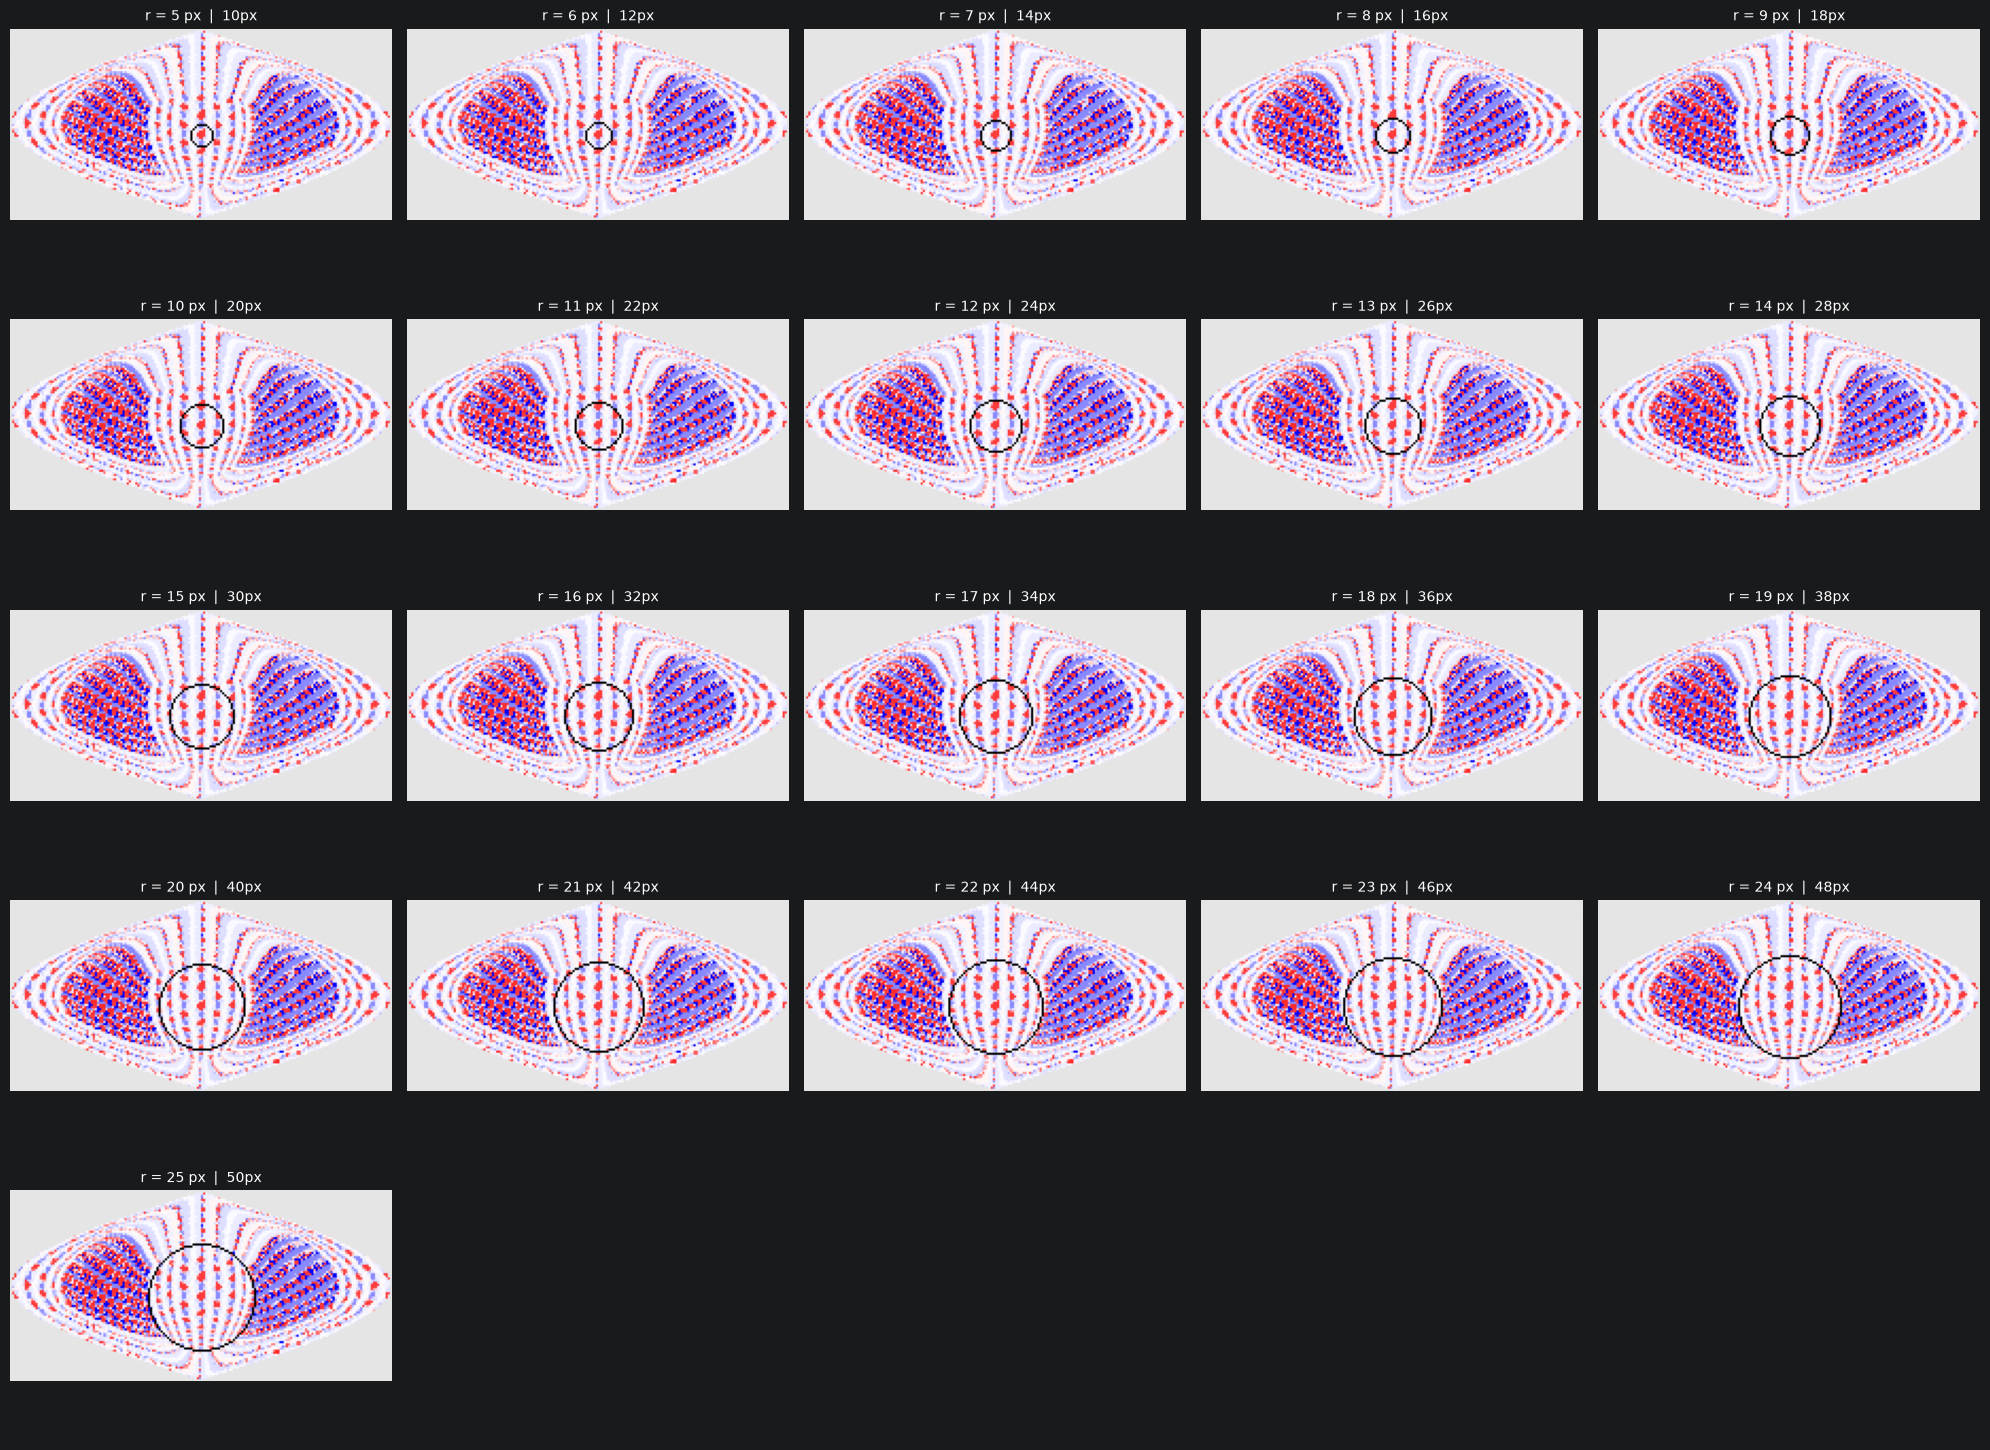

In [76]:
n_maps = len(generated_maps)
n_cols = PREVIEW_COLUMNS
n_rows = ceil(n_maps / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4.0 * n_cols, 3.0 * n_rows),
)

# Make axes iterable also when only one row/column is present.
if n_maps == 1:
    axes = [axes]
else:
    axes = axes.ravel()

for ax, item in zip(axes, generated_maps):
    ax.imshow(item["image"])
    ax.set_title(
        f"r = {item['radius_px']} px  |  {item['label']}",
        fontsize=10,
    )
    ax.axis("off")

for ax in axes[n_maps:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Saved files

Run this cell to print every generated filename and its corresponding radius.


In [77]:
for item in generated_maps:
    print(
        f"radius {item['radius_px']:>2} px  ->  "
        f"{item['path'].name}"
    )


radius  5 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_10px.png
radius  6 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_12px.png
radius  7 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_14px.png
radius  8 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_16px.png
radius  9 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_18px.png
radius 10 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_20px.png
radius 11 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_22px.png
radius 12 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_24px.png
radius 13 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_26px.png
radius 14 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_28px.png
radius 15 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_30px.png
radius 16 px  ->  03_Nylon7415_70A_final_clean_aligned_bfactor_map_clean_32px.png
radius 17 px  ->